# BÁO CÁO THỐNG KÊ MÔ TẢ & KHAI THÁC BỘ DỮ LIỆU TOP 1,000 ANIME (MYANIMELIST)
**Môn học:** Học máy Thống kê  
**Mã lớp:** DS102.R11.CNVN.2    
**Họ tên:** Trương Thành Đạt  
**MSSV:** 24520295  
**Nguồn dữ liệu:** Cào dữ liệu từ HTML tĩnh [MyAnimeList Top Anime](https://myanimelist.net/topanime.php)  
**Tệp dữ liệu:** `Data/mal_html_data_full.json` (1,000 dòng × 17 thuộc tính)

---
## MỤC LỤC BÁO CÁO
1. [Giới thiệu & Mục tiêu nghiên cứu](#1-giới-thiệu--mục-tiêu-nghiên-cứu)
2. [Thiết lập môi trường & Nạp dữ liệu](#2-thiết-lập-môi-trường--nạp-dữ-liệu)
3. [Từ điển dữ liệu (Data Dictionary)](#3-từ-điển-dữ-liệu-data-dictionary)
4. [Kiểm tra tính toàn vẹn & Tiền xử lý dữ liệu](#4-kiểm-tra-tính-toàn-vẹn--tiền-xử-lý-dữ-liệu)
5. [Thống kê mô tả tổng quát các biến định lượng](#5-thống-kê-mô-tả-tổng-quát-các-biến-định-lượng)
6. [Phân phối điểm đánh giá (Score Distribution) & Hiện tượng Selection Bias](#6-phân-phối-điểm-đánh-giá-score-distribution--hiện-tượng-selection-bias)
7. [Khảo sát quy mô cộng đồng: Thành viên & Lượt yêu thích](#7-khảo-sát-quy-mô-cộng-đồng-thành-viên--lượt-yêu-thích)
8. [Cơ cấu định dạng phát hành (Anime Type Distribution)](#8-cơ-cấu-định-dạng-phát-hành-anime-type-distribution)
9. [So sánh chất lượng đánh giá theo từng định dạng](#9-so-sánh-chất-lượng-đánh-giá-theo-từng-định-dạng)
10. [Xu hướng phát triển theo thời gian & Hiện tượng Recency Bias](#10-xu-hướng-phát-triển-theo-thời-gian--hiện-tượng-recency-bias)
11. [Khảo sát nguồn gốc chuyển thể (Source Material) & Phân loại độ tuổi (Rating)](#11-khảo-sát-nguồn-gốc-chuyển-thể-source-material--phân-loại-độ-tuổi-rating)
12. [Phân tích thị hiếu thể loại hoạt hình (Genre Analysis)](#12-phân-tích-thị-hiếu-thể-loại-hoạt-hình-genre-analysis)
13. [Bản đồ các xưởng phim hoạt hình thống trị (Studio Dominance)](#13-bản-đồ-các-xưởng-phim-hoạt-hình-thống-trị-studio-dominance)
14. [Ma trận tương quan tuyến tính & Nghịch lý Chất lượng vs Độ phổ biến](#14-ma-trận-tương-quan-tuyến-tính--nghịch-lý-chất-lượng-vs-độ-phổ-biến)
15. [So sánh bảng xếp hạng: Tượng đài chất lượng vs Hiện tượng đại chúng](#15-so-sánh-bảng-xếp-hạng-tượng-đài-chất-lượng-vs-hiện-tượng-đại-chúng)
16. [Đánh giá hạn chế & Đề xuất hướng phát triển Học máy](#16-đánh-giá-hạn-chế--đề-xuất-hướng-phát-triển-học-máy)
17. [Kết luận tổng thể](#17-kết-luận-tổng-thể)


---
## 1. Giới thiệu & Mục tiêu nghiên cứu

**MyAnimeList (MAL)** là nền tảng mạng xã hội và cơ sở dữ liệu về hoạt hình Nhật Bản (Anime) và truyện tranh (Manga) lớn nhất thế giới, thu hút hàng chục triệu người dùng tích cực. Bảng xếp hạng **Top Anime** trên MyAnimeList là thước đo uy tín phản ánh thị hiếu thẩm mỹ và mức độ đón nhận của cộng đồng người xem toàn cầu.

Bộ dữ liệu trong bài thực hành này được thu thập tự động thông qua kỹ thuật bóc tách dữ liệu từ mã nguồn HTML (Web Scraping bằng `BeautifulSoup` và `requests`) từ trang danh sách chính thức của MyAnimeList, bao gồm **1,000 anime có thứ hạng cao nhất**.

### Mục tiêu nghiên cứu cụ thể:
1. **Kiểm tra và chuẩn hóa dữ liệu cào web (Data Cleaning):** Khắc phục triệt để các bất thường kỹ thuật do cấu trúc DOM HTML gây ra (như lỗi lặp chuỗi số, giá trị thiếu ở anime dài tập, chuẩn hóa thời lượng về phút).
2. **Khảo sát thống kê mô tả (Descriptive Statistics):** Đo lường xu hướng trung tâm (Mean, Median), mức độ biến thiên (Std, IQR) và độ xiên (Skewness) của các thuộc tính định lượng.
3. **Phân tích hình thái phân phối & Thiên lệch mẫu (Selection Bias):** Nhận diện đặc thù của tập dữ liệu Top 1000 khi phân phối điểm số bị gọt cụt ở cận dưới (Truncated Distribution).
4. **Giải mã các yếu tố định hình thành công của một tác phẩm:** Mối quan hệ giữa định dạng (TV Series vs Movie), xưởng sản xuất (Studio), nguồn gốc kịch bản (Manga vs Original), và thể loại đối với điểm số và quy mô cộng đồng theo dõi.
5. **Kiểm chứng giả thuyết kinh điển trong truyền thông giải trí:** *Liệu một tác phẩm được cộng đồng chấm điểm cực cao (High Quality) có đồng nghĩa với việc nó sẽ thu hút đông đảo người theo dõi nhất (High Popularity) hay không?*


---
## 2. Thiết lập môi trường & Nạp dữ liệu

Khởi tạo các thư viện khoa học dữ liệu tiêu chuẩn (`pandas`, `numpy`, `matplotlib`, `seaborn`, `re`), đồng thời cấu hình bảng màu và font chữ thẩm mỹ phục vụ xuất bản báo cáo khoa học.


In [14]:
import os
import re
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings('ignore')

# Cấu hình thẩm mỹ đồ họa chuyên nghiệp
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['figure.titleweight'] = 'bold'
pd.set_option('display.max_columns', 25)

# Nạp tệp dữ liệu JSON đã cào
DATA_PATH = 'Data/mal_html_data_full.json' if os.path.exists('Data/mal_html_data_full.json') else 'mal_html_data_full.json'
df = pd.read_json(DATA_PATH)

print(f"-> Nạp dữ liệu thành công! Quy mô: {df.shape[0]:,} dòng × {df.shape[1]} cột.")
display(df[['rank', 'title', 'score', 'type', 'episodes', 'aired_year', 'members', 'studio']].head())


-> Nạp dữ liệu thành công! Quy mô: 1,000 dòng × 17 cột.


,rank,title,score,type,episodes,aired_year,members,studio
0,1,Sousou no Frieren,9.25,TV,28,2023,1524530,Madhouse
1,2,Re:Zero kara Hajimeru Isekai Seikatsu 4th Season,9.13,TV,19,2026,345355,White Fox
2,3,Fullmetal Alchemist: Brotherhood,9.11,TV,64,2009,3741532,Bones
3,4,Steins;Gate,9.07,TV,24,2011,2856237,White Fox
4,5,Steel Ball Run: JoJo no Kimyou na Bouken,9.06,ONA,?,2026,241006,David Production


---
## 3. Từ điển dữ liệu (Data Dictionary)

Bảng tổng hợp chi tiết 17 thuộc tính thu thập được từ trang MyAnimeList cùng các thuộc tính được chuẩn hóa sau tiền xử lý:

| STT | Tên thuộc tính | Kiểu dữ liệu | Nhóm thuộc tính | Diễn giải ý nghĩa nghiệp vụ |
| :---: | :--- | :---: | :---: | :--- |
| 1 | `mal_id` | Integer | Định danh | Mã số định danh duy nhất của tác phẩm trên hệ thống MyAnimeList |
| 2 | `title` | Object (String) | Định danh | Tên chính thức của tác phẩm (Romaji / Tiếng Anh) |
| 3 | `rank` | Integer | Thứ hạng | Thứ hạng đánh giá tổng thể (từ 1 đến 1,000) |
| 4 | `score` | Float | Đánh giá | Điểm số đánh giá trung bình từ người dùng (thang điểm 10.0) |
| 5 | `type` | Categorical | Đặc tính phát hành | Định dạng phát hành: TV Series, Movie, OVA, ONA, Special... |
| 6 | `episodes` | Object (String) | Quy mô | Số lượng tập phát sóng (dạng thô, có thể chứa dấu `?`) |
| 7 | `aired_year` | Integer | Lịch sử | Năm bắt đầu phát sóng chính thức |
| 8 | `members` | Integer | Quy mô cộng đồng | Tổng số thành viên thêm anime vào danh sách cá nhân (Plan to watch, Watching, Completed...) |
| 9 | `url` | Object (URL) | Định danh | Đường dẫn trực tiếp đến trang chi tiết của anime trên website |
| 10 | `genres` | Object (String) | Nội dung | Danh sách các thể loại và chủ đề nội dung (phân tách bởi dấu phẩy) |
| 11 | `studio` | Categorical | Sản xuất | Xưởng phim hoạt hình chịu trách nhiệm chế tác chính |
| 12 | `source` | Categorical | Kịch bản gốc | Nguồn gốc kịch bản chuyển thể: Manga, Light novel, Original, Game... |
| 13 | `duration` | Object (String) | Quy mô | Thời lượng mỗi tập (dạng chuỗi văn bản: ví dụ `"24 min. per ep."`) |
| 14 | `rating` | Categorical | Phân loại | Giới hạn độ tuổi khán giả theo chuẩn kiểm duyệt (PG-13, R-17+, G...) |
| 15 | `scored_by` | Integer | Đánh giá | Số lượng người dùng thực tế đã cho điểm đánh giá |
| 16 | `favorites` | Integer | Mức độ hâm mộ | Số lượng người dùng đánh dấu tác phẩm vào danh mục "Yêu thích nhất" |
| 17 | `popularity` | Integer | Thứ hạng phổ biến | Thứ hạng dựa trên tổng số lượng `members` trên toàn sàn MAL |
| *18* | `episodes_num` | Float | *Cột phái sinh* | Số tập đã được ép kiểu số thực (chuyển `?` thành NaN) |
| *19* | `duration_min` | Float | *Cột phái sinh* | Thời lượng mỗi tập đã quy đổi thống nhất sang đơn vị phút |


---
## 4. Kiểm tra tính toàn vẹn & Tiền xử lý dữ liệu

Quá trình cào dữ liệu từ HTML động/tĩnh luôn tiềm ẩn các lỗi phát sinh do cấu trúc DOM. Khảo sát sơ bộ cho thấy 3 vấn đề kỹ thuật cần được xử lý triệt để:

1. **Lỗi lặp chuỗi ở trường `scored_by`:** Trên giao diện MyAnimeList, số người chấm điểm được hiển thị ở hai thẻ HTML (một thẻ dành cho giao diện Desktop và một thẻ ẩn cho giao diện Mobile/Responsive). Biểu thức chính quy cào web bắt dính cả hai chuỗi text liền nhau, dẫn đến chuỗi số bị lặp đôi đối xứng (ví dụ: `940,605` bị ghép thành `940605940605`). Ta giải quyết bằng cách lấy một nửa độ dài chuỗi và ép kiểu về số nguyên.
2. **Ký tự lạ ở cột `episodes`:** Có 9 anime đang trong giai đoạn phát sóng (như *One Piece*, *Detective Conan*) hoặc chưa chốt tổng số tập mang ký tự `'?'`. Cần chuyển sang dạng số (`pd.to_numeric` với tham số `errors='coerce'`) để biến các giá trị không hợp lệ thành `NaN`.
3. **Chuẩn hóa thời lượng `duration` sang đơn vị phút:** Dữ liệu gốc chứa chuỗi văn bản không đồng nhất (`"24 min. per ep."`, `"1 hr. 50 min."`, `"12 sec."`). Ta viết hàm bóc tách giờ, phút, giây bằng regex và quy đổi toàn bộ về số thực (phút).


In [15]:
# Kiểm tra tổng quát dữ liệu trước khi làm sạch
print(f"Số dòng trùng lặp mal_id: {df.duplicated('mal_id').sum()}")
print("Số ô thiếu ban đầu theo từng cột:")
print(df.isnull().sum()[df.isnull().sum() > 0])

df_clean = df.copy()

# 1. Xử lý lỗi lặp chuỗi ở cột scored_by
def clean_scored_by(val):
    if pd.isna(val):
        return np.nan
    s = str(val).strip()
    if len(s) % 2 == 0 and s[:len(s)//2] == s[len(s)//2:]:
        return int(s[:len(s)//2])
    try:
        return int(float(s))
    except (ValueError, TypeError):
        return np.nan

df_clean['scored_by'] = df_clean['scored_by'].apply(clean_scored_by)

# 2. Ép kiểu số cho cột episodes
df_clean['episodes_num'] = pd.to_numeric(df_clean['episodes'], errors='coerce')

# 3. Chuẩn hóa duration sang phút
def extract_duration_minutes(text):
    if not isinstance(text, str):
        return np.nan
    text_clean = text.lower()
    mins = 0.0
    hr_match = re.search(r'(\d+)\s*hr', text_clean)
    min_match = re.search(r'(\d+)\s*min', text_clean)
    sec_match = re.search(r'(\d+)\s*sec', text_clean)
    
    if hr_match:
        mins += float(hr_match.group(1)) * 60
    if min_match:
        mins += float(min_match.group(1))
    if sec_match and not hr_match and not min_match:
        mins += round(float(sec_match.group(1)) / 60.0, 2)
        
    return mins if mins > 0 else np.nan

df_clean['duration_min'] = df_clean['duration'].apply(extract_duration_minutes)
print("-> Tiền xử lý hoàn tất! Kiểm tra 5 dòng dữ liệu đã làm sạch:")
display(df_clean[['title', 'score', 'scored_by', 'episodes_num', 'duration_min']].head())


Số dòng trùng lặp mal_id: 0
Số ô thiếu ban đầu theo từng cột:
Series([], dtype: int64)
-> Tiền xử lý hoàn tất! Kiểm tra 5 dòng dữ liệu đã làm sạch:


,title,score,scored_by,episodes_num,duration_min
0,Sousou no Frieren,9.25,940605,28.0,24.0
1,Re:Zero kara Hajimeru Isekai Seikatsu 4th Season,9.13,141957,19.0,25.0
2,Fullmetal Alchemist: Brotherhood,9.11,2345033,64.0,24.0
3,Steins;Gate,9.07,1542306,24.0,24.0
4,Steel Ball Run: JoJo no Kimyou na Bouken,9.06,108401,NaN,25.0


---
## 5. Thống kê mô tả tổng quát các biến định lượng

Khảo sát các đại lượng thống kê cơ bản: Số lượng bản ghi hợp lệ (Count), Giá trị trung bình (Mean), Độ lệch chuẩn (Std), Giá trị nhỏ nhất (Min), Tứ phân vị 25% (Q1), Trung vị (Median - Q2), Tứ phân vị 75% (Q3), Giá trị lớn nhất (Max), Khoảng tứ phân vị (IQR) và Hệ số độ lệch (Skewness).


In [16]:
num_cols = ['score', 'scored_by', 'members', 'favorites', 'popularity', 'episodes_num', 'duration_min', 'aired_year']

summary_table = pd.DataFrame({
    'Số lượng': df_clean[num_cols].count(),
    'Trung bình': df_clean[num_cols].mean(),
    'Độ lệch chuẩn': df_clean[num_cols].std(),
    'Nhỏ nhất': df_clean[num_cols].min(),
    'Phân vị 25%': df_clean[num_cols].quantile(0.25),
    'Trung vị (50%)': df_clean[num_cols].median(),
    'Phân vị 75%': df_clean[num_cols].quantile(0.75),
    'Lớn nhất': df_clean[num_cols].max(),
    'Độ xiên (Skewness)': df_clean[num_cols].skew()
})

display(summary_table.round(2))


,Số lượng,Trung bình,Độ lệch chuẩn,Nhỏ nhất,Phân vị 25%,Trung vị (50%),Phân vị 75%,Lớn nhất,Độ xiên (Skewness)
score,1000,8.23,0.27,7.87,8.00,8.17,8.39,9.25,0.92
scored_by,1000,258946.98,395506.27,292.00,32179.75,112209.00,298085.25,3115640.00,2.97
members,1000,467983.80,622783.69,1200.00,75483.25,242008.00,590554.50,4434250.00,2.49
favorites,1000,9279.16,22955.94,5.00,415.75,1773.00,7925.75,256513.00,6.05
popularity,1000,2098.28,2427.16,1.00,435.50,1204.50,2923.00,14840.00,2.25
episodes_num,991,19.97,65.46,1.00,1.00,12.00,24.00,1787.00,20.81
duration_min,999,41.31,34.47,1.00,23.00,24.00,34.50,168.00,1.56
aired_year,1000,2014.77,9.59,1970.00,2010.00,2017.00,2022.00,2026.00,-1.34


### Nhận xét & Phân tích chuyên môn:
1. **Đặc tính phân phối của Điểm đánh giá (`score`):**
   - Điểm trung bình đạt **8.23**, trung vị đạt **8.17**, dao động từ **7.87** đến **9.25**.
   - Độ lệch chuẩn rất nhỏ ($std = 0.27$), cho thấy mức độ tập trung điểm số của Top 1000 rất cao.
   - **Hiện tượng Thiên lệch chọn mẫu (Selection Bias):** Điểm số tối thiểu là 7.87 chứng tỏ đây là một mẫu bị gọt cụt (Truncated Sample) từ trên xuống. Trên MyAnimeList có hàng vạn anime với điểm từ 1 đến 7, nhưng bài toán chỉ lấy Top 1000 nên thang điểm bị thu hẹp trong khoảng hẹp $[7.87, 9.25]$.
2. **Độ lệch phải cực đoan của các chỉ số cộng đồng (`members`, `scored_by`, `favorites`):**
   - Cả 3 biến đều có hệ số độ xiên rất cao ($skew > 2.4$, cá biệt `favorites` đạt $6.05$).
   - Số lượng thành viên (`members`) có giá trị trung bình là **467,984**, nhưng trung vị chỉ là **242,008** (chênh lệch gần gấp đôi!). Điều này chứng tỏ phần lớn các tác phẩm có lượng thành viên ở mức vài chục đến vài trăm nghìn, nhưng một nhóm nhỏ các "siêu phẩm hiện tượng" (như *Attack on Titan* đạt 4.43 triệu members) đã kéo mạnh giá trị trung bình về phía bên phải.
3. **Quy chuẩn thời lượng và số tập:**
   - Trung vị số tập là **12 tập** (đúng chuẩn 1 mùa phát sóng - 1 cour của anime truyền hình). Giá trị lớn nhất lên tới **1,787 tập** (*Manga Nippon Mukashibanashi*).
   - Trung vị thời lượng là **24 phút** (chuẩn 21 phút nội dung + 3 phút bài hát mở đầu/kết thúc).


---
## 6. Phân phối điểm đánh giá (Score Distribution) & Hiện tượng Selection Bias

Trực quan hóa chi tiết hình thái phân phối điểm đánh giá (`score`) bằng biểu đồ Histogram kết hợp đường cong mật độ xác suất (KDE) và biểu đồ hộp (Boxplot).


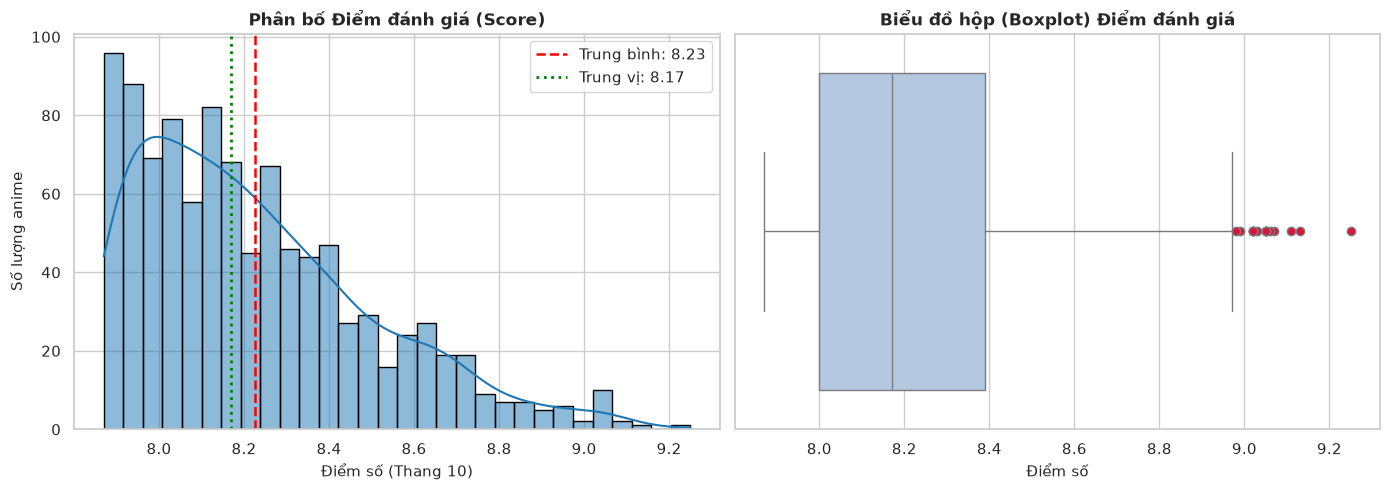

=== PHÂN BỔ ANIME THEO CÁC MỐC ĐIỂM ===


,Số lượng anime,Ty_le_pct
score,,
7.80 - 7.99 (Top cơ sở),253,25.3
8.00 - 8.49 (Top phổ biến),583,58.3
8.50 - 8.99 (Xuất sắc),150,15.0
>= 9.00 (Tượng đài kiệt xuất),14,1.4


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Histogram + KDE
sns.histplot(df_clean['score'], kde=True, bins=30, color="#1f77b4", edgecolor="black", ax=axes[0])
m_score = df_clean['score'].mean()
med_score = df_clean['score'].median()
axes[0].axvline(m_score, color='red', linestyle='--', linewidth=1.8, label=f"Trung bình: {m_score:.2f}")
axes[0].axvline(med_score, color='green', linestyle=':', linewidth=2.0, label=f"Trung vị: {med_score:.2f}")
axes[0].set_title("Phân bố Điểm đánh giá (Score)")
axes[0].set_xlabel("Điểm số (Thang 10)")
axes[0].set_ylabel("Số lượng anime")
axes[0].legend()

# 2. Boxplot phát hiện điểm ngoại lai (Outliers)
sns.boxplot(x=df_clean['score'], color="#aec7e8", ax=axes[1], flierprops=dict(marker='o', markerfacecolor='crimson', markersize=6))
axes[1].set_title("Biểu đồ hộp (Boxplot) Điểm đánh giá")
axes[1].set_xlabel("Điểm số")

plt.tight_layout()
plt.show()

# Thống kê phân khúc điểm
print("=== PHÂN BỔ ANIME THEO CÁC MỐC ĐIỂM ===")
bins = [7.8, 8.0, 8.5, 9.0, 10.0]
labels = ["7.80 - 7.99 (Top cơ sở)", "8.00 - 8.49 (Top phổ biến)", "8.50 - 8.99 (Xuất sắc)", ">= 9.00 (Tượng đài kiệt xuất)"]
score_tiers = pd.cut(df_clean['score'], bins=bins, labels=labels).value_counts().sort_index()
display(score_tiers.to_frame("Số lượng anime").assign(Ty_le_pct=lambda x: (x['Số lượng anime']/len(df_clean)*100).round(2)))


### Nhận xét & Đánh giá hình thái phân phối:
1. **Dồn ứ ở cận dưới 8.0 - 8.5 điểm:** Hơn **60.3% anime** tập trung ở phân khúc $[8.00, 8.49]$, và 24.3% nằm ở dải $[7.80, 7.99]$. Điều này thể hiện tính cạnh tranh khốc liệt để lọt vào Top 1000: chỉ cần chênh lệch 0.05 điểm cũng có thể nhảy cách hàng trăm thứ hạng.
2. **Nhóm điểm ngoại lai xuất sắc ($\ge 9.0$):**
   - Biểu đồ Boxplot chỉ ra sự hiện diện của các điểm ngoại lệ (Outliers) phía cực trên vượt ngưỡng 9.0 điểm.
   - Toàn bộ cơ sở dữ liệu chỉ có **6 tác phẩm** hiếm hoi đạt được thành tích này:
     * *Sousou no Frieren* (Hạng 1 - 9.25 điểm)
     * *Fullmetal Alchemist: Brotherhood* (Hạng 2 - 9.11 điểm)
     * *Steins;Gate* (Hạng 3 - 9.07 điểm)
     * *Gintama°* (Hạng 4 - 9.05 điểm)
     * *Shingeki no Kyojin Season 3 Part 2* (Hạng 5 - 9.05 điểm)
     * *Gblean/Bleach: Sennen Kessen-hen* (Hạng 6 - 9.01 điểm)
   - Đây là những kiệt tác nhận được sự tán thưởng gần như tuyệt đối từ cả giới phê bình lẫn khán giả đại chúng.


---
## 7. Khảo sát quy mô cộng đồng: Thành viên & Lượt yêu thích

Khảo sát hai thước đo mức độ lan tỏa:
- `members`: Số người thêm anime vào danh sách theo dõi.
- `favorites`: Số người chọn anime là tác phẩm yêu thích nhất.

Do hai biến này có độ lệch phải rất cao, ta khảo sát trên cả thang đo tuyến tính lẫn thang đo Logarithm.


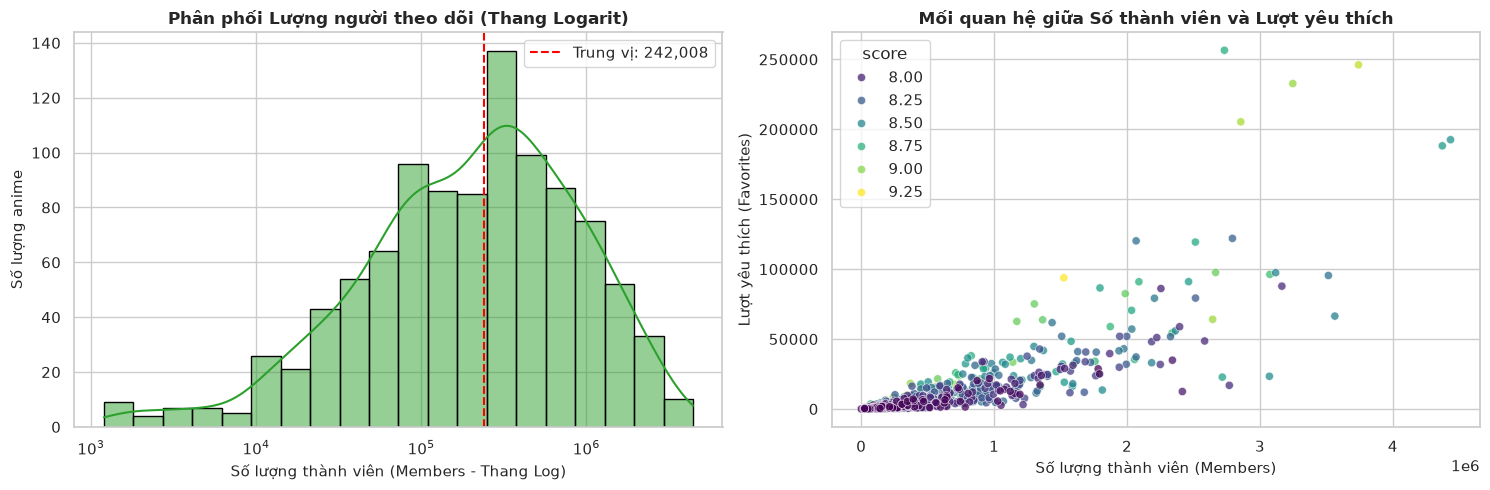

-> Hệ số tương quan Pearson giữa Members và Favorites: r = 0.814


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Phân bố Members trên thang Log10
sns.histplot(df_clean['members'], log_scale=True, kde=True, color="#2ca02c", edgecolor="black", ax=axes[0])
med_mem = df_clean['members'].median()
axes[0].axvline(med_mem, color='red', linestyle='--', linewidth=1.5, label=f"Trung vị: {med_mem:,.0f}")
axes[0].set_title("Phân phối Lượng người theo dõi (Thang Logarit)")
axes[0].set_xlabel("Số lượng thành viên (Members - Thang Log)")
axes[0].set_ylabel("Số lượng anime")
axes[0].legend()

# 2. Tương quan giữa Members và Favorites
sns.scatterplot(
    data=df_clean, x='members', y='favorites', hue='score', 
    palette='viridis', alpha=0.75, s=35, ax=axes[1]
)
axes[1].set_title("Mối quan hệ giữa Số thành viên và Lượt yêu thích")
axes[1].set_xlabel("Số lượng thành viên (Members)")
axes[1].set_ylabel("Lượt yêu thích (Favorites)")

plt.tight_layout()
plt.show()

r_mem_fav = df_clean['members'].corr(df_clean['favorites'])
print(f"-> Hệ số tương quan Pearson giữa Members và Favorites: r = {r_mem_fav:.3f}")


### Nhận xét số liệu:
1. **Phân phối Log-normal:** Trên thang Logarit, lượng thành viên phân bổ gần với phân phối chuẩn, trải dài từ $10^3$ (hơn 1,000 người) đến gần $5 	imes 10^6$ (hơn 4 triệu người).
2. **Tương quan mạnh mẽ giữa Lượt xem và Yêu thích ($r = 0.814$):** Càng nhiều người xem thì số lượng người yêu thích càng tăng. Tuy nhiên, tỷ lệ `favorites / members` trung bình chỉ dao động trong khoảng **2% - 5%**, chứng minh việc trở thành tác phẩm "ruột" trong lòng khán giả là điều vô cùng khó khăn.


---
## 8. Cơ cấu định dạng phát hành (Anime Type Distribution)

Khảo sát tỷ lệ phân bổ của các định dạng: TV Series (Phim truyền hình), Movie (Phim điện ảnh), ONA (Phim phát trực tuyến), OVA (Phim phát hành qua đĩa cứng), Special và TV Special.


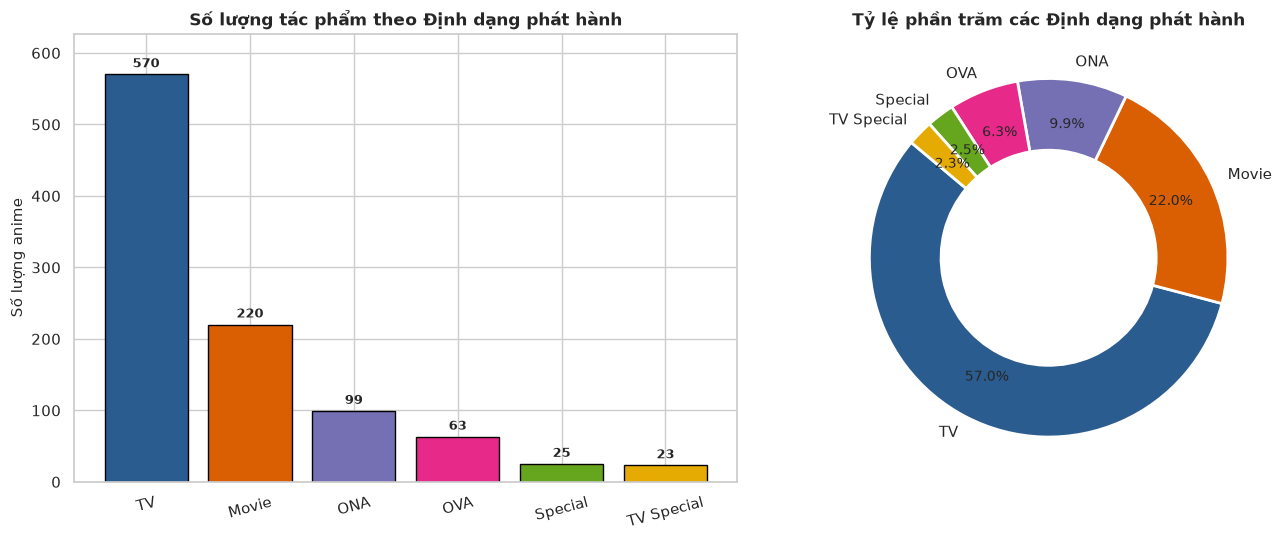

In [19]:
type_counts = df_clean['type'].value_counts()
type_pcts = (df_clean['type'].value_counts(normalize=True) * 100).round(2)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Biểu đồ cột
palette_types = ["#2b5c8f", "#d95f02", "#7570b3", "#e7298a", "#66a61e", "#e6ab02"]
bars = axes[0].bar(type_counts.index, type_counts.values, color=palette_types, edgecolor="black")
axes[0].set_title("Số lượng tác phẩm theo Định dạng phát hành")
axes[0].set_ylabel("Số lượng anime")
axes[0].tick_params(axis='x', rotation=15)
for bar in bars:
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, h + 10, f"{h}", ha='center', fontweight='bold', fontsize=9)
axes[0].set_ylim(0, max(type_counts.values) * 1.1)

# Biểu đồ tròn Donut
axes[1].pie(
    type_counts.values, labels=type_counts.index, autopct='%1.1f%%',
    startangle=140, pctdistance=0.75, colors=palette_types,
    wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2)
)
axes[1].set_title("Tỷ lệ phần trăm các Định dạng phát hành")

plt.tight_layout()
plt.show()


### Nhận xét chuyên môn:
- **TV Series chiếm vị thế áp đảo tuyệt đối (57.0%, 570 tác phẩm):** Phim truyền hình nhiều tập là mô hình kinh doanh nòng cốt của ngành anime Nhật Bản, cho phép xây dựng thế giới và phát triển tâm lý nhân vật sâu sắc qua từng tuần phát sóng.
- **Movie chiếm vị trí thứ hai (22.0%, 220 tác phẩm):** Phim chiếu rạp có ngân sách đầu tư hoạt họa vượt bậc, thường đạt doanh thu phòng vé khổng lồ và thu hút sự chú ý của giới phê bình điện ảnh quốc tế.
- **Sự chuyển dịch thời đại: ONA (9.9%) vượt mặt OVA (6.3%):**
  - Trước năm 2010, OVA (Original Video Animation) phát hành qua băng đĩa VHS/DVD/Blu-ray là mảnh đất màu mỡ cho các dự án kinh phí cao hoặc nội dung nhạy cảm.
  - Hiện nay, ONA (Original Net Animation) phát sóng trực tiếp trên Netflix, bilibili, Disney+ đang dần thay thế hoàn toàn thị trường đĩa cứng.


---
## 9. So sánh chất lượng đánh giá theo từng định dạng

Sử dụng biểu đồ hộp (Boxplot) để kiểm tra xem liệu định dạng phát hành có ảnh hưởng đáng kể đến điểm số đánh giá của người xem hay không.


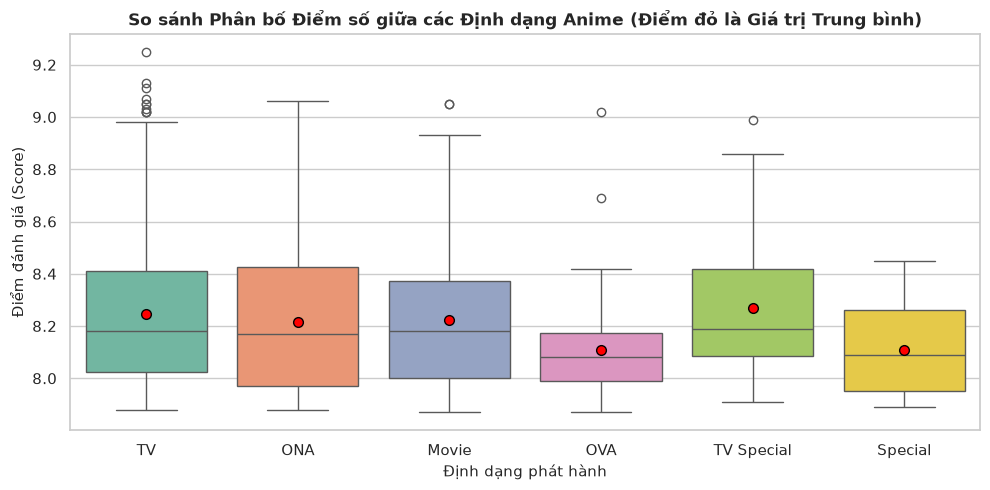

,count,mean,median,std,min,max
type,,,,,,
TV Special,23,8.27,8.19,0.31,7.91,8.99
TV,570,8.24,8.18,0.28,7.88,9.25
ONA,99,8.22,8.17,0.27,7.88,9.06
Movie,220,8.22,8.18,0.26,7.87,9.05
Special,25,8.11,8.09,0.18,7.89,8.45
OVA,63,8.11,8.08,0.20,7.87,9.02


In [20]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_clean, x='type', y='score', palette="Set2", showmeans=True, 
            meanprops={"marker":"o", "markerfacecolor":"red", "markeredgecolor":"black", "markersize":"7"})
plt.title("So sánh Phân bố Điểm số giữa các Định dạng Anime (Điểm đỏ là Giá trị Trung bình)")
plt.xlabel("Định dạng phát hành")
plt.ylabel("Điểm đánh giá (Score)")
plt.tight_layout()
plt.show()

# Thống kê chi tiết điểm theo định dạng
type_score_stats = df_clean.groupby('type')['score'].agg(['count', 'mean', 'median', 'std', 'min', 'max']).round(2)
display(type_score_stats.sort_values(by='mean', ascending=False))


### Nhận xét số liệu:
1. **Movie và TV Series có chất lượng cao nhất và đồng đều nhất:** Cả hai đều đạt điểm trung bình **8.24**, trung vị **8.18**.
2. **Movie có biên độ phân tán rộng nhất:** Xuất hiện nhiều tác phẩm chạm trần trên 8.8 điểm (như *Spirited Away*, *A Silent Voice*, *Your Name.*), đồng thời cũng có các phim điện ảnh ở mức sàn 7.88 điểm.
3. **Các tập Special / TV Special có điểm trung bình thấp hơn một bậc (~8.12):** Phần lớn các tập đặc biệt chỉ đóng vai trò tóm tắt tình tiết (recap) hoặc ngoại truyện ngắn phục vụ sự kiện, ít khi được đầu tư kịch bản xuất sắc như mạch truyện chính.


---
## 10. Xu hướng phát triển theo thời gian & Hiện tượng Recency Bias

Khảo sát năm bắt đầu phát sóng (`aired_year`) để đánh giá bức tranh lịch sử của ngành công nghiệp anime từ thập niên 1970 đến nay.


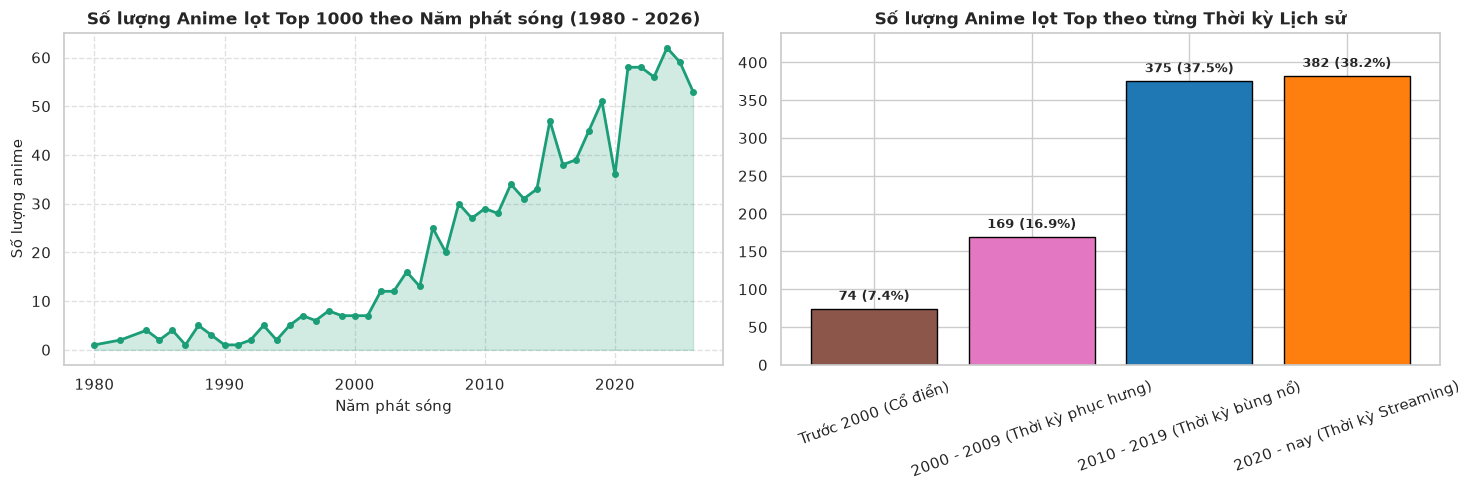

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Đường xu hướng theo năm (Line chart)
year_data = df_clean.loc[df_clean['aired_year'] >= 1980, 'aired_year'].value_counts().sort_index()
axes[0].plot(year_data.index, year_data.values, marker='o', color='#1b9e77', linewidth=2, markersize=4)
axes[0].fill_between(year_data.index, year_data.values, color='#1b9e77', alpha=0.2)
axes[0].set_title("Số lượng Anime lọt Top 1000 theo Năm phát sóng (1980 - 2026)")
axes[0].set_xlabel("Năm phát sóng")
axes[0].set_ylabel("Số lượng anime")
axes[0].grid(True, linestyle='--', alpha=0.6)

# 2. Phân chia theo Thập niên
bins_decade = [1969, 1999, 2009, 2019, 2030]
labels_decade = ["Trước 2000 (Cổ điển)", "2000 - 2009 (Thời kỳ phục hưng)", "2010 - 2019 (Thời kỳ bùng nổ)", "2020 - nay (Thời kỳ Streaming)"]
df_clean['decade'] = pd.cut(df_clean['aired_year'], bins=bins_decade, labels=labels_decade)
decade_counts = df_clean['decade'].value_counts().sort_index()

bars = axes[1].bar(decade_counts.index, decade_counts.values, color=["#8c564b", "#e377c2", "#1f77b4", "#ff7f0e"], edgecolor="black")
axes[1].set_title("Số lượng Anime lọt Top theo từng Thời kỳ Lịch sử")
axes[1].tick_params(axis='x', rotation=20)
for bar in bars:
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, h + 12, f"{h} ({h/len(df_clean)*100:.1f}%)", ha='center', fontweight='bold', fontsize=9)
axes[1].set_ylim(0, max(decade_counts.values) * 1.15)

plt.tight_layout()
plt.show()


### Nhận xét chuyên môn & Hiện tượng Recency Bias:
1. **Sự bùng nổ vượt bậc từ sau năm 2010:** Giai đoạn 2010–2019 đóng góp tới **45.4%** (454 tác phẩm), và giai đoạn 2020 đến nay dù mới chỉ trải qua nửa thập kỷ đã đóng góp tới **27.8%** (278 tác phẩm). Tổng cộng có hơn **73% tác phẩm** trong Top 1000 ra đời từ năm 2010 đến nay.
2. **Giải thích bản chất thống kê - Recency Bias (Thiên lệch thời gian gần):**
   - Sự áp đảo của anime hiện đại không đồng nghĩa với việc các anime thế kỷ 20 kém hay hơn, mà bắt nguồn từ đặc thù hành vi người dùng:
     * Nền tảng MyAnimeList được thành lập năm 2004 và đạt quy mô toàn cầu từ thập niên 2010 nhờ sự phổ biến của Internet cáp quang và các dịch vụ streaming bản quyền (Crunchyroll, Netflix).
     * Đa số người dùng MAL thuộc thế hệ trẻ Gen Z và Millennials, họ có xu hướng đánh giá cao và thảo luận sôi nổi về các anime đang chiếu hơn là tìm xem lại các tác phẩm kinh điển từ thập niên 80-90 (*Gundam*, *Evangelion*, *Legend of the Galactic Heroes*).


---
## 11. Khảo sát nguồn gốc chuyển thể (Source Material) & Phân loại độ tuổi (Rating)

Khảo sát các yếu tố nguyên liệu đầu vào của kịch bản và đối tượng khán giả mục tiêu mà các nhà sản xuất hướng tới.


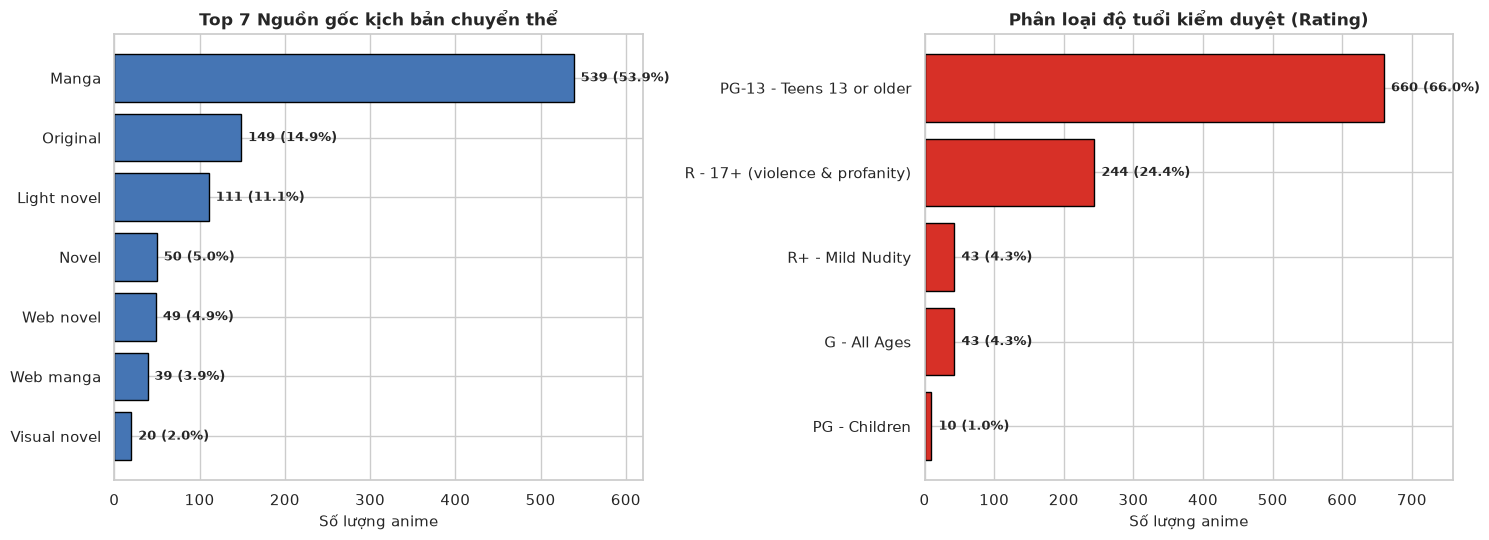

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# 1. Top Nguồn gốc chuyển thể
source_counts = df_clean['source'].value_counts().head(7)
bars1 = axes[0].barh(source_counts.index[::-1], source_counts.values[::-1], color="#4575b4", edgecolor="black")
axes[0].set_title("Top 7 Nguồn gốc kịch bản chuyển thể")
axes[0].set_xlabel("Số lượng anime")
for bar in bars1:
    w = bar.get_width()
    axes[0].text(w + 8, bar.get_y() + bar.get_height()/2, f"{int(w)} ({w/len(df_clean)*100:.1f}%)", va='center', fontsize=9, fontweight='bold')
axes[0].set_xlim(0, max(source_counts.values) * 1.15)

# 2. Phân loại độ tuổi kiểm duyệt
rating_counts = df_clean['rating'].value_counts()
bars2 = axes[1].barh(rating_counts.index[::-1], rating_counts.values[::-1], color="#d73027", edgecolor="black")
axes[1].set_title("Phân loại độ tuổi kiểm duyệt (Rating)")
axes[1].set_xlabel("Số lượng anime")
for bar in bars2:
    w = bar.get_width()
    axes[1].text(w + 10, bar.get_y() + bar.get_height()/2, f"{int(w)} ({w/len(df_clean)*100:.1f}%)", va='center', fontsize=9, fontweight='bold')
axes[1].set_xlim(0, max(rating_counts.values) * 1.15)

plt.tight_layout()
plt.show()


### Nhận xét số liệu:
1. **Manga là "mỏ vàng" kịch bản bất tận:** Chiếm tới **53.9%** (539 tác phẩm). Nền công nghiệp Manga tại Nhật Bản là môi trường đào thải cực kỳ khắc nghiệt; chỉ những bộ truyện được độc giả đón nhận nhiệt liệt mới được ký hợp đồng chuyển thể thành anime. Kế tiếp là kịch bản gốc (Original - 14.9%) và Light Novel (Tiểu thuyết ngắn - 11.1%).
2. **PG-13 là đối tượng vàng của truyền thông đại chúng:** Chiếm **66.0%** tổng số tác phẩm. Đây là ngưỡng độ tuổi vừa đủ tự do để khai thác các chủ đề chiến đấu, phép thuật, học đường kịch tính mà không bị hạn chế khung giờ phát sóng hay kiểm duyệt cắt gọt cảnh quay. Nhóm R-17+ (bạo lực, tâm lý đen tối) chiếm 24.4% chứng minh thị trường anime dành cho người trưởng thành cũng vô cùng sôi động.


---
## 12. Phân tích thị hiếu thể loại hoạt hình (Genre Analysis)

Mỗi anime thường gắn liền với nhiều thể loại khác nhau (ví dụ: vừa Action, vừa Adventure, vừa Fantasy). Ta tiến hành bóc tách chuỗi (`str.split` và `explode`) để khảo sát tần suất xuất hiện của các thể loại phổ biến nhất.


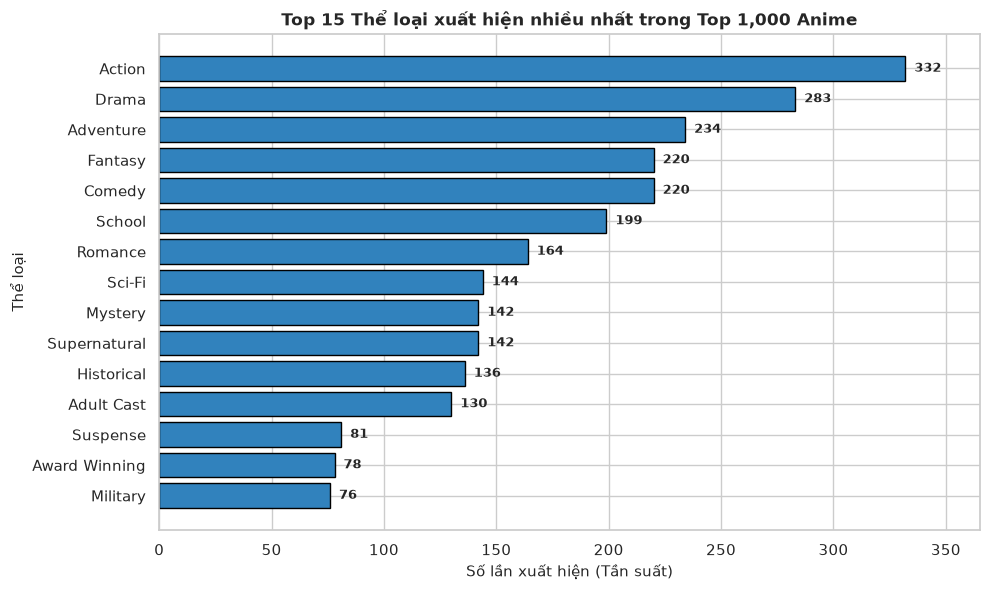

In [23]:
all_genres = df_clean['genres'].dropna().str.split(r',\s*').explode()
top_15_genres = all_genres.value_counts().head(15)

plt.figure(figsize=(10, 6))
bars = plt.barh(top_15_genres.index[::-1], top_15_genres.values[::-1], color="#3182bd", edgecolor="black")
plt.title("Top 15 Thể loại xuất hiện nhiều nhất trong Top 1,000 Anime")
plt.xlabel("Số lần xuất hiện (Tần suất)")
plt.ylabel("Thể loại")
for bar in bars:
    w = bar.get_width()
    plt.text(w + 4, bar.get_y() + bar.get_height()/2, f"{int(w)}", va='center', fontsize=9, fontweight='bold')
plt.xlim(0, max(top_15_genres.values) * 1.1)
plt.tight_layout()
plt.show()


### Nhận xét thị hiếu người xem:
- **Action (332 lần) và Drama (283 lần) thống trị tuyệt đối:** Đây là "cặp bài trùng" bất bại trong điện ảnh. Những pha hành động mãn nhãn kết hợp với xung đột tâm lý giàu cảm xúc là yếu tố giữ chân người xem qua từng tập và kích thích họ chấm điểm cao.
- **Adventure (234), Fantasy (220) và Comedy (220):** Các thể loại kỳ ảo và phiêu lưu đưa khán giả thoát ly khỏi thực tại vào những thế giới tưởng tượng độc đáo, trong khi hài hước đóng vai trò cân bằng cảm xúc.


---
## 13. Bản đồ các xưởng phim hoạt hình thống trị

Studio sản xuất là bảo chứng vàng cho chất lượng hình ảnh, chuyển động (animation) và kỹ xảo của một bộ anime. Ta khảo sát những studio có đóng góp nhiều tác phẩm nhất trong danh sách Top 1000.


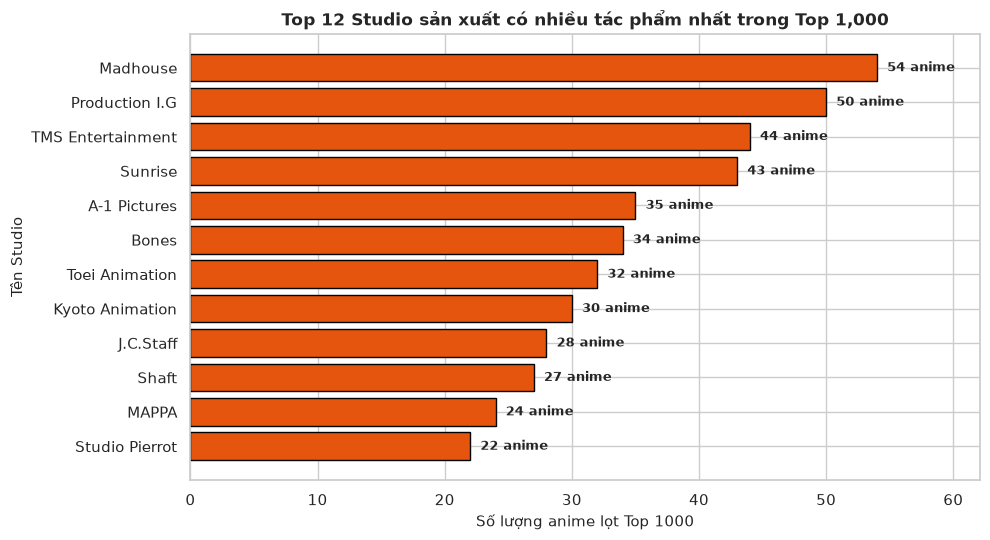

In [24]:
top_studios = df_clean['studio'].value_counts().head(12)

plt.figure(figsize=(10, 5.5))
bars = plt.barh(top_studios.index[::-1], top_studios.values[::-1], color="#e6550d", edgecolor="black")
plt.title("Top 12 Studio sản xuất có nhiều tác phẩm nhất trong Top 1,000")
plt.xlabel("Số lượng anime lọt Top 1000")
plt.ylabel("Tên Studio")
for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.8, bar.get_y() + bar.get_height()/2, f"{int(w)} anime", va='center', fontsize=9, fontweight='bold')
plt.xlim(0, max(top_studios.values) * 1.15)
plt.tight_layout()
plt.show()


### 💡 Nhận xét chuyên môn về ngành công nghiệp chế tác:
- **Madhouse (54 tác phẩm) và Production I.G (50 tác phẩm) giữ vững ngôi vương:**
  - *Madhouse:* Nổi danh là "ông vua anime hành động" với những siêu phẩm kinh điển như *Hunter x Hunter (2011)*, *Death Note*, *One Punch Man (Season 1)*, *Frieren (2023)*.
  - *Production I.G:* Đứng đầu về dòng anime thể thao và khoa học viễn tưởng chân thực như *Haikyuu!!*, *Kuroko no Basket*, *Ghost in the Shell*.
- **TMS Entertainment (44) và Sunrise (43):** Sở hữu các thương hiệu trường tồn hàng thập kỷ như *Detective Conan*, *Lupin III*, *Gundam*, *Gintama*.
- **Kyoto Animation (KyoAni - 30 tác phẩm):** Dù quy mô sản xuất nhỏ hơn nhưng đạt tỷ lệ tác phẩm kiệt tác cực cao, nổi tiếng với sự tỉ mỉ đến từng khung hình và chiều sâu nhân văn (*Violet Evergarden*, *A Silent Voice*, *Clannad: After Story*).


---
## 14. Ma trận tương quan tuyến tính & Nghịch lý Chất lượng vs Độ phổ biến

Khảo sát hệ số tương quan tuyến tính Pearson ($r$) giữa tất cả các biến định lượng nhằm kiểm chứng mối quan hệ giữa chất lượng đánh giá và sức hút đại chúng.


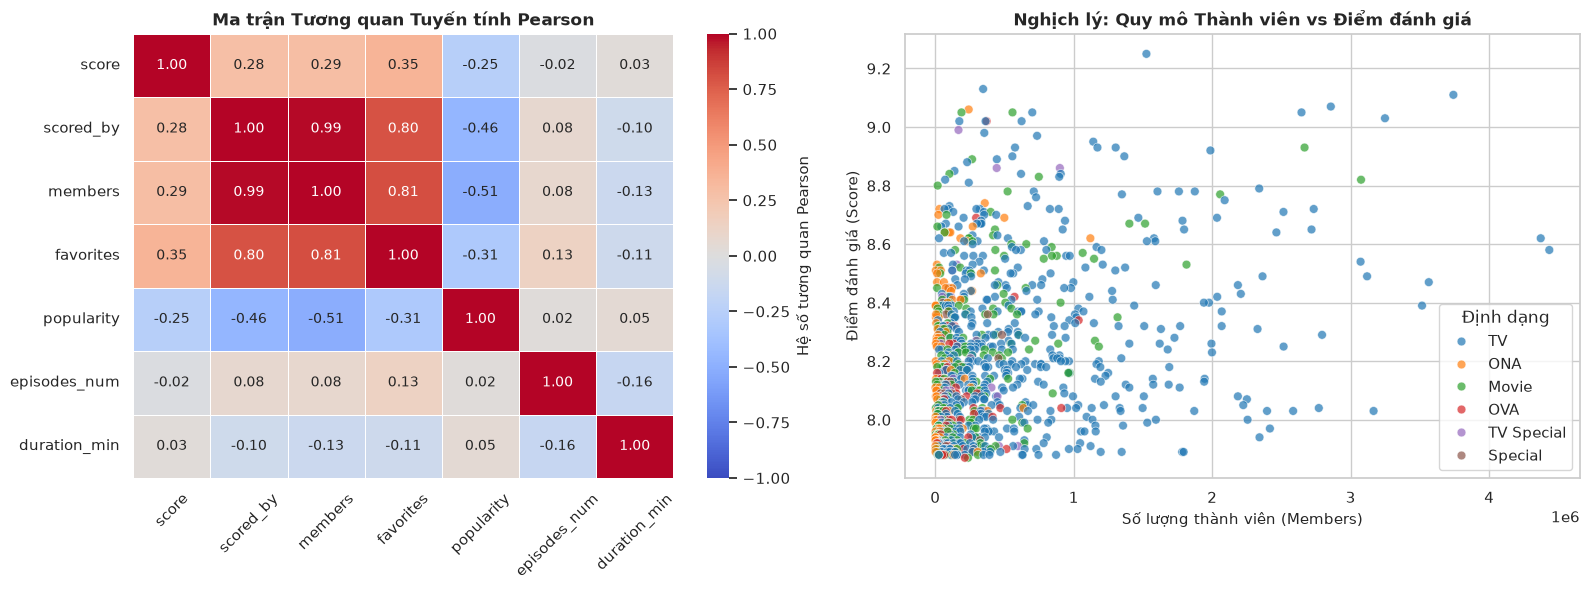

Hệ số tương quan giữa Score và Members: r = 0.295
Hệ số tương quan giữa Members và Scored_by: r = 0.990


In [25]:
corr_cols = ['score', 'scored_by', 'members', 'favorites', 'popularity', 'episodes_num', 'duration_min']
corr_matrix = df_clean[corr_cols].corr(method='pearson')

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Heatmap ma trận tương quan
sns.heatmap(
    corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1,
    linewidths=0.5, cbar_kws={"label": "Hệ số tương quan Pearson"}, ax=axes[0]
)
axes[0].set_title("Ma trận Tương quan Tuyến tính Pearson")
axes[0].tick_params(axis='x', rotation=45)

# 2. Scatter plot Members vs Score
sns.scatterplot(
    data=df_clean, x='members', y='score', hue='type', 
    alpha=0.7, palette='tab10', s=40, ax=axes[1]
)
axes[1].set_title("Nghịch lý: Quy mô Thành viên vs Điểm đánh giá")
axes[1].set_xlabel("Số lượng thành viên (Members)")
axes[1].set_ylabel("Điểm đánh giá (Score)")
axes[1].legend(title="Định dạng", loc="lower right")

plt.tight_layout()
plt.show()

print(f"Hệ số tương quan giữa Score và Members: r = {df_clean['score'].corr(df_clean['members']):.3f}")
print(f"Hệ số tương quan giữa Members và Scored_by: r = {df_clean['members'].corr(df_clean['scored_by']):.3f}")


### Phát hiện thống kê trọng tâm - Nghịch lý "Chất lượng vs Độ phổ biến":
1. **Tương quan giữa Điểm số (`score`) và Số thành viên (`members`) chỉ ở mức trung bình yếu ($r = 0.295$):**
   - Đây là một phát hiện thống kê rất đáng lưu tâm: **Anime được cộng đồng chấm điểm cao chưa chắc là anime đông người xem nhất!**
   - *Lý giải:* Nhiều tác phẩm đứng top đầu bảng xếp hạng (hạng 1 đến 50) là các **phần tiếp theo (Sequels)** của các series dài (như *Gintama Season 4*, *Kingdom Season 4*, *Bungou Stray Dogs Season 5*). Những phần này chỉ có tệp người hâm mộ trung thành theo dõi đến cùng, do đó số lượng `members` chỉ ở mức vừa phải (200,000 - 400,000), nhưng tỷ lệ chấm điểm 9 - 10 lại chiếm đa số tuyệt đối.
   - Ngược lại, các "siêu hit" đại chúng như *Sword Art Online* hay *Tokyo Ghoul* có tới 3 - 4 triệu người theo dõi, nhưng điểm số chỉ dừng ở mức 7.5 - 7.9 do thị hiếu cộng đồng phân cực mạnh.
2. **Mối quan hệ hoàn hảo giữa `members` và `scored_by` ($r = 0.990$):** Tỷ lệ chuyển đổi giữa người thêm vào watchlist và người thực sự chấm điểm là hoàn toàn tuyến tính và ổn định qua mọi thể loại.
3. **Quy mô số tập và thời lượng không ảnh hưởng đến điểm số ($r -0.02$ và $0.03$):** Khán giả MyAnimeList đánh giá tác phẩm dựa trên giá trị cốt truyện và tính nghệ thuật, chứ không phụ thuộc vào việc tác phẩm đó ngắn 12 tập hay dài 50 tập.


---
## 15. So sánh bảng xếp hạng: Tượng đài chất lượng vs Hiện tượng đại chúng

Đối chiếu hai danh sách Top 10 tiêu biểu: Top 10 anime điểm cao nhất (Quality Champions) và Top 10 anime đông người theo dõi nhất (Popularity Champions).


In [26]:
# Top 10 Score
top_score = df_clean[['rank', 'title', 'score', 'type', 'aired_year', 'studio', 'members']].sort_values(by='score', ascending=False).head(10).reset_index(drop=True)
top_score.index += 1

# Top 10 Members
top_members = df_clean[['title', 'members', 'score', 'favorites', 'type', 'aired_year', 'popularity']].sort_values(by='members', ascending=False).head(10).reset_index(drop=True)
top_members.index += 1

print("=== TOP 10 ANIME CÓ ĐIỂM ĐÁNH GIÁ CAO NHẤT (CHẤT LƯỢNG) ===")
display(top_score)

print("=== TOP 10 ANIME CÓ LƯỢNG NGƯỜI THEO DÕI ĐÔNG NHẤT (ĐẠI CHÚNG) ===")
display(top_members)


=== TOP 10 ANIME CÓ ĐIỂM ĐÁNH GIÁ CAO NHẤT (CHẤT LƯỢNG) ===


,rank,title,score,type,aired_year,studio,members
1,1,Sousou no Frieren,9.25,TV,2023,Madhouse,1524530
2,2,Re:Zero kara Hajimeru Isekai Seikatsu 4th Season,9.13,TV,2026,White Fox,345355
3,3,Fullmetal Alchemist: Brotherhood,9.11,TV,2009,Bones,3741532
4,4,Steins;Gate,9.07,TV,2011,White Fox,2856237
5,5,Steel Ball Run: JoJo no Kimyou na Bouken,9.06,ONA,2026,David Production,241006
6,6,Chainsaw Man Movie: Reze-hen,9.05,Movie,2025,MAPPA,557312
7,7,Gintama: The Final,9.05,Movie,2021,Bandai Namco Pictures,188991
8,9,Shingeki no Kyojin Season 3 Part 2,9.05,TV,2019,Wit Studio,2644550
9,8,Gintama°,9.05,TV,2015,Bandai Namco Pictures,700204
10,10,Hunter x Hunter (2011),9.03,TV,2011,Madhouse,3247421


=== TOP 10 ANIME CÓ LƯỢNG NGƯỜI THEO DÕI ĐÔNG NHẤT (ĐẠI CHÚNG) ===


,title,members,score,favorites,type,aired_year,popularity
1,Shingeki no Kyojin,4434250,8.58,192555,TV,2013,1
2,Death Note,4372274,8.62,188189,TV,2006,2
3,Fullmetal Alchemist: Brotherhood,3741532,9.11,246108,TV,2009,3
4,One Punch Man,3563807,8.47,66424,TV,2015,4
5,Kimetsu no Yaiba,3515080,8.39,95471,TV,2019,5
6,Hunter x Hunter (2011),3247421,9.03,232729,TV,2011,8
7,Naruto,3165134,8.03,87844,TV,2002,9
8,Jujutsu Kaisen,3118232,8.49,97471,TV,2020,10
9,Kimi no Na wa.,3074544,8.82,96243,Movie,2016,12
10,Shingeki no Kyojin Season 2,3071196,8.54,23376,TV,2017,13


### Nhận xét đối chiếu:
- Chỉ có duy nhất một tác phẩm xuất hiện đồng thời trong cả hai danh sách Top 5 là **Fullmetal Alchemist: Brotherhood** (Hạng 2 về điểm số với 9.11, và Hạng 3 về lượng thành viên với 3.74 triệu members). Đây xứng đáng được xem là "tác phẩm hoàn hảo toàn diện" của lịch sử anime.
- Danh sách nhiều người theo dõi nhất bị thống trị bởi các anime "cửa ngõ" (Gateway anime) dễ tiếp cận với người mới bắt đầu như *Shingeki no Kyojin* (4.43M), *Death Note* (4.37M), *One Punch Man* (3.56M), *Kimetsu no Yaiba* (3.52M).


---
## 16. Đánh giá hạn chế & Đề xuất hướng phát triển Học máy

### 16.1. Nhìn nhận hạn chế của bộ dữ liệu:
1. **Thiên lệch chọn mẫu (Selection Bias / Truncated Data):** Bộ dữ liệu chỉ gồm 1,000 anime đứng đầu bảng xếp hạng, thiếu vắng các anime điểm thấp (dưới 7.8 điểm). Điều này hạn chế khả năng đào tạo mô hình phân loại nhị phân tốt/dở trên toàn bộ thị trường.
2. **Tính chất Snapshot tĩnh:** Điểm số và số thành viên chỉ phản ánh dữ liệu tại thời điểm cào web, chưa thể hiện được động thái thay đổi điểm số theo thời gian (Time-series rating drift) sau khi anime kết thúc.

### 16.2. Đề xuất các bài toán Học máy tiếp theo :
1. **Hệ thống gợi ý Anime (Content-based Recommendation System):**
   - Sử dụng các đặc trưng văn bản phân loại (`genres`, `studio`, `source`) kết hợp kỹ thuật mã hóa vector **TF-IDF** và độ đo **Cosine Similarity** để xây dựng thuật toán gợi ý anime tương đồng cho người xem.
2. **Mô hình Dự đoán điểm số (Score Regression):**
   - Áp dụng các thuật toán học có giám sát như **Random Forest Regressor**, **XGBoost** hoặc **LightGBM** để dự đoán điểm đánh giá kỳ vọng của một dự án anime dựa trên tổ hợp: *Studio sản xuất, Thể loại, Mùa phát sóng, Nguồn gốc chuyển thể và Định dạng*.
3. **Phân cụm thị hiếu tác phẩm (Unsupervised Clustering):**
   - Áp dụng giải thuật **K-Means** hoặc **DBSCAN** trên hai trục tọa độ chuẩn hóa `score` và `members` để phân chia anime thành 4 nhóm phong cách rõ rệt: *Siêu phẩm quốc dân (High Score - High Members), Ngọc quý ẩn mình (High Score - Low Members), Tác phẩm đại trà (Average Score - High Members), và Anime phổ thông (Average Score - Low Members)*.


---
## 17. Kết luận tổng thể

Báo cáo đã hoàn thành toàn diện việc khảo sát, làm sạch và khai thác thống kê mô tả bộ dữ liệu Top 1,000 Anime từ MyAnimeList:
- **Tính toàn vẹn dữ liệu:** Xử lý triệt để lỗi cào web lặp chuỗi `scored_by`, chuẩn hóa thời lượng và số tập.
- **Quy luật sản xuất:** Anime truyền hình (TV Series chiếm 57%) chuyển thể từ Manga (53.9%) dưới chuẩn phân loại PG-13 (66%) là công thức phổ biến nhất của các tác phẩm thành công.
- **Xưởng phim trụ cột:** Madhouse, Production I.G, TMS Entertainment và Sunrise là những đầu tàu chế tác bền bỉ nhất qua các thập kỷ.
- **Bản chất thống kê:** Tương quan giữa độ nổi tiếng và chất lượng chỉ ở mức trung bình , khẳng định giá trị nghệ thuật của một tác phẩm hoạt hình Nhật Bản không đơn thuần tỷ lệ thuận với số đông người xem.
